# Воронка и retention

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep, proportion_confint, proportion_effectsize, proportions_ztest,
)

ROOT = Path.cwd().parent
env = dict(
    line.strip().split('=', 1)
    for line in (ROOT / '.env').read_text().splitlines()
    if '=' in line and not line.startswith('#')
)
conninfo = psycopg.conninfo.make_conninfo(
    host=env['POSTGRES_HOST'], port=env['POSTGRES_PORT'], dbname=env['POSTGRES_DB'],
    user=env['POSTGRES_USER'], password=env['POSTGRES_PASSWORD'],
)


def q(sql):
    with psycopg.connect(conninfo) as conn, conn.cursor() as cur:
        cur.execute(sql)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])


def compare(x_a, n_a, x_b, n_b):
    """z-тест двух долей и разница a - b в п.п. с 95% ДИ."""
    z, p = proportions_ztest([x_a, x_b], [n_a, n_b])
    lo, hi = confint_proportions_2indep(x_a, n_a, x_b, n_b, method='wald')
    return {
        'p_a': x_a / n_a, 'p_b': x_b / n_b,
        'diff_pp': (x_a / n_a - x_b / n_b) * 100, 'ci_lo_pp': lo * 100, 'ci_hi_pp': hi * 100,
        'z': z, 'p_value': p,
    }


names = {'p_a': 'p_android', 'p_b': 'p_ios'}

## 1. Воронка по платформам

In [2]:
funnel = q("""
    select segment as platform, step_no, step, users, conv_first::float as conv_first
    from mart.funnel
    where dim = 'platform'
""")
wide = funnel.pivot(index=['step_no', 'step'], columns='platform', values='conv_first').droplevel('step_no')
wide.round(4)

platform,android,ios,web
step,,,
signup_started,1.0000,1.0000,1.0000
signup_completed,0.6986,0.7008,0.7005
onboarding_completed,0.3364,0.4143,0.4206
activation,0.1676,0.2136,0.2078


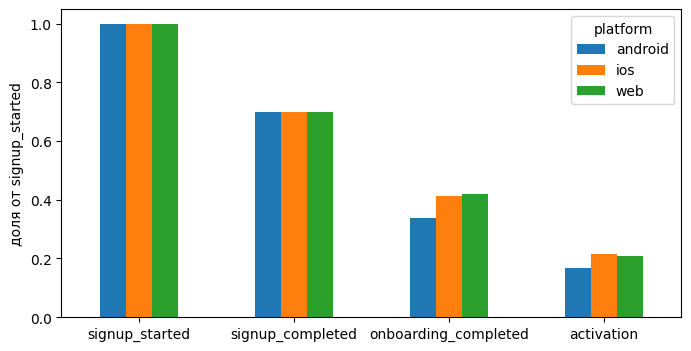

In [3]:
ax = wide.plot.bar(rot=0, figsize=(8, 4))
ax.set_xlabel('')
ax.set_ylabel('доля от signup_started')
plt.show()

Из 19 955 человек, начавших регистрацию, до активации доходят 3 830 (19%).

Больше всего теряем на онбординге: из 13 964 зарегистрировавшихся его проходят 7 584, то есть отваливается 46%. Это крупнейшая потеря и в абсолютных числах (6 380 человек), и в процентах. На регистрации теряем 30%, после онбординга до первого проекта доходит примерно половина.

По платформам картина почти одинаковая везде, кроме онбординга: регистрацию завершают ~70% на всех платформах, активируются после онбординга ~50% тоже везде. А онбординг на android проходят 48% против 59-60% на ios и web. Из-за этого итоговая конверсия android 16.8% против 21.4% у ios.

## 2. Онбординг: android vs ios

In [4]:
users = funnel.pivot(index='platform', columns='step_no', values='users')
pd.Series(compare(users.at['android', 3], users.at['android', 2], users.at['ios', 3], users.at['ios', 2])).rename(names).round(4)

p_android     0.4816
p_ios         0.5912
diff_pp     -10.9607
ci_lo_pp    -12.7450
ci_hi_pp     -9.1763
z           -11.9548
p_value       0.0000
dtype: float64

Разница -11.0 п.п. (48.2% против 59.1%), 95% ДИ [-12.7; -9.2], z = -11.95, p < 0.001. Интервал далеко от нуля, это не шум.

В абсолютных числах: если бы android проходил онбординг как ios, за 12 недель было бы примерно на 690 онбордингов больше и, при той же конверсии дальше, примерно на 345 активаций больше. Это +23% к активациям android, около 29 человек в неделю.

## 3. Android vs ios внутри channel и country

In [5]:
# те же условия, что depth >= 2 и depth >= 3 в mart.funnel
ob = q("""
    select platform, channel, country,
           count(*)::int as n,
           count(onboarding_ts)::int as onboarded
    from mart.users
    where platform in ('android', 'ios')
      and signup_started_ts is not null
      and signup_completed_ts is not null
    group by 1, 2, 3
""")

rows = []
for dim in ['channel', 'country']:
    g = ob.groupby([dim, 'platform'])[['n', 'onboarded']].sum()
    for seg in g.index.get_level_values(0).unique():
        a, i = g.loc[(seg, 'android')], g.loc[(seg, 'ios')]
        rows.append({'dim': dim, 'segment': seg, 'n_android': a.n, 'n_ios': i.n,
                     **compare(a.onboarded, a.n, i.onboarded, i.n)})

pd.DataFrame(rows).rename(columns=names).set_index(['dim', 'segment']).round(4)

n_android  n_ios  p_android   p_ios  diff_pp  ci_lo_pp  \
dim     segment                                                               
channel ads               1259   1126     0.5091  0.6137 -10.4542  -14.4183   
        organic           2490   2224     0.4779  0.5782 -10.0326  -12.8719   
        paid_social       1571   1405     0.4570  0.5964 -13.9408  -17.4973   
        referral           980    832     0.4949  0.5865  -9.1641  -13.7462   
country BY                 635    562     0.4850  0.5907 -10.5708  -16.1954   
        KZ                1269   1145     0.4909  0.5852  -9.4215  -13.3850   
        RU                3768   3305     0.4788  0.5946 -11.5785  -13.8907   
        UZ                 628    575     0.4761  0.5843 -10.8233  -16.4344   

                     ci_hi_pp       z  p_value  
dim     segment                                 
channel ads           -6.4902 -5.1328   0.0000  
        organic       -7.1932 -6.8860   0.0000  
        paid_social  -10.3842 -7.6012   0.0000  
        referral      -4.5819 -3.8986   0.0001  
country BY            -4.9462 -3.6593   0.0003  
        KZ            -5.4580 -4.6347   0.0000  
        RU            -9.2664 -9.7378   0.0000  
        UZ            -5.2122 -3.7562   0.0002

Хотел исключить простое объяснение: может, на android просто больше пользователей из слабых каналов или стран. Но разница держится внутри каждого канала и каждой страны отдельно (от -9.2 до -13.9 п.п., везде p < 0.001). Значит, дело не в составе аудитории.

Ограничения: каналы и страны проверены по отдельности, без комбинаций. И это всё ещё наблюдательные данные. Могут быть факторы, которых в данных нет (модели устройств, скорость интернета), поэтому сказать "онбординг на android плохой" можно только после эксперимента.

## 4. Retention по каналам


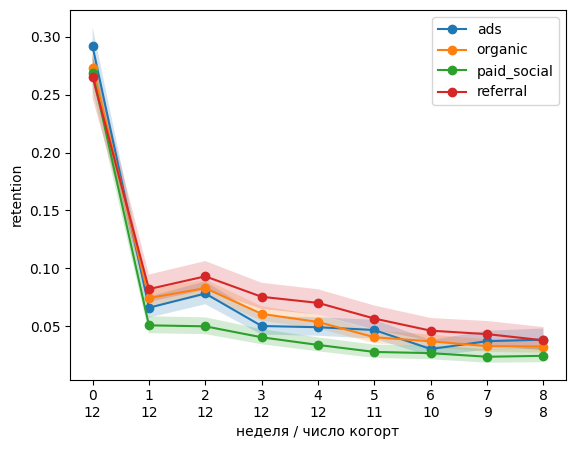

In [6]:
raw = q("""
    select segment as channel, cohort_week, week_n, cohort_size::int as cohort_size, retained::int as retained
    from mart.retention_by_segment
    where dim = 'channel' and week_n <= 8
""")
ret = raw.groupby(['channel', 'week_n'])[['cohort_size', 'retained']].sum().reset_index()
ret['retention'] = ret.retained / ret.cohort_size
ret['lo'], ret['hi'] = proportion_confint(ret.retained, ret.cohort_size, method='wilson')
cohorts = raw.groupby('week_n').cohort_week.nunique()

fig, ax = plt.subplots()
for ch, d in ret.groupby('channel'):
    ax.plot(d.week_n, d.retention, marker='o', label=ch)
    ax.fill_between(d.week_n, d.lo, d.hi, alpha=0.2)
ax.set_xticks(cohorts.index, [f'{w}\n{n}' for w, n in cohorts.items()])
ax.set_xlabel('неделя / число когорт')
ax.set_ylabel('retention')
ax.legend()
plt.show()

In [7]:
ret.pivot(index='week_n', columns='channel', values='retention').assign(cohorts=cohorts).round(4)

channel,ads,organic,paid_social,referral,cohorts
week_n,,,,,
0,0.2917,0.2734,0.2691,0.2654,12
1,0.0660,0.0743,0.0508,0.0821,12
2,0.0783,0.0829,0.0499,0.0931,12
3,0.0502,0.0607,0.0404,0.0754,12
4,0.0491,0.0537,0.0338,0.0702,12
5,0.0467,0.0405,0.0278,0.0566,11
6,0.0303,0.0370,0.0268,0.0462,10
7,0.0371,0.0328,0.0236,0.0432,9
8,0.0384,0.0324,0.0245,0.0378,8


paid_social хуже всех на неделях 1-8: на 1-й неделе 5.1% против 7.4% у organic, на 4-й 3.4% против 5.4%, то есть примерно в 1.5 раза ниже, и интервалы не пересекаются. Referral лучший на неделях 1-7 (на 1-й 8.2%, на 4-й 7.0%).

Интересно, что на неделе 0 (это по сути активация) каналы почти не отличаются: от 26.5% у referral до 29.2% у ads, и referral тут даже самый низкий. Значит, разница между каналами не в том, кто лучше активируется, а в том, кто потом возвращается.

К 8-й неделе интервалы сильно расширяются: там остаётся 8 когорт из 12, и вернувшихся в канале от 50 до 120 человек. Разницу между referral, organic и ads на 8-й неделе по этим данным утверждать нельзя.

Ещё одна особенность: неделя 2 выше недели 1 почти во всех каналах. Первый возврат обычно случается через неделю после активации, а активация бывает в любой из первых 7 дней, поэтому часть первых возвратов попадает во 2-ю неделю от регистрации.

## 5. Размер выборки для A/B-теста онбординга на android

In [8]:
# последняя cohort_week неполная, в среднее не берём
flow = q("""
    select cohort_week, count(*)::int as users
    from mart.users
    where platform = 'android'
      and signup_started_ts is not null
      and signup_completed_ts is not null
      and cohort_week < (select max(cohort_week) from mart.users)
    group by 1
    order by 1
""")
wk = flow.users.mean()
print(f'android в неделю: {wk:.0f} (по {len(flow)} неделям)')

p0 = 0.48
rows = []
for mde in [0.03, 0.05]:
    h = proportion_effectsize(p0 + mde, p0)
    n = int(np.ceil(NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8, alternative='two-sided')))
    rows.append({'mde_pp': mde * 100, 'n_per_group': n, 'n_total': 2 * n, 'weeks_needed': int(np.ceil(2 * n / wk))})
pd.DataFrame(rows)

android в неделю: 525 (по 12 неделям)


,mde_pp,n_per_group,n_total,weeks_needed
0,3.0,4359,8718,17
1,5.0,1569,3138,6


Чтобы поймать улучшение онбординга android на 3 п.п. (с 48% до 51%), нужно 4 359 человек на группу, 8 718 всего. При текущем потоке ~525 android-регистраций в неделю это 17 недель. Слишком долго для теста одного экрана.

Что можно сделать:
- поднять MDE до 5 п.п.: 1 569 на группу, 6 недель. Если изменение не даёт хотя бы 5 п.п., его, скорее всего, и внедрять не стоит;
- если новый онбординг одинаковый для всех платформ, тестировать на всех: поток вырастет примерно в 2.2 раза;
- до теста добавить события по каждому экрану онбординга. Сейчас видно только, что android теряет людей где-то внутри онбординга, но не на каком шаге. С такими событиями гипотезу можно сузить и проверять быстрее.